# Seminario IAO - Protocolo común

Para una decisión de alto riesgo como conceder un crédito, ¿es mejor usar un modelo interpretable por diseño o una caja negra explicada a posteriori?

Este notebook es **común a los subgrupos (A,B)** y se ejecuta **al principio una sola vez**. Lo que hace:

1. Escribe `common_protocol.py` en la carpeta compartida: parámetros, partición, preprocesado, validación cruzada, métricas, umbral, equidad, auditoría y formato de resultados. Los notebooks del subgrupo A y B lo importan, por lo que **ambos usan el mismo código**.
2. Descarga los datos y crea la partición común (los apartados 1.4-1.6).
3. Al final, junta los resultados del subgrupo A y B en la tabla comparativa (el apartado 5.1).

**Orden de ejecución para cuando presentemos:** este notebook hasta el 1.6 -> notebooks A y B (en cualquier orden) -> sección 5.1 de este notebook.

# Configuración

In [1]:
from google.colab import drive
import os, sys, importlib
# Esta carpeta de Drive que pongo os la comparto a todos
FOLDER = "/content/drive/MyDrive/Seminario_IAO"
try:
    drive.mount("/content/drive")
except ImportError:
    FOLDER = "Seminario_IAO"
os.makedirs(FOLDER, exist_ok=True)
if FOLDER not in sys.path:
    sys.path.insert(0, FOLDER)

Mounted at /content/drive


# Protocolo común (`common_protocol.py`)

Esta celda se encarga de escribir el archivo en la carpeta compartida. (**IMPORTANTE: CUALQUIER CAMBIO QUE QUERAIS HACER COMO SEMILLA, COSTES, NÚMERO DE PARTICIONESLO QUE SEA SE CAMBIA AQUÍ**)

In [59]:
%%writefile {FOLDER}/common_protocol.py 
# Esto es una instrucción especial para copiar el archivo en el drive
"""Protocolo común del seminario IAO (subgrupos A y B).
Como he dicho antes, cualquier cambio de antes se hace aquí y se vuelve a ejecutar todo."""
import os, itertools
import numpy as np
import pandas as pd
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, recall_score # roc_auc -> área bajo la curva ROC

# Parámetros acordados en la propuesta
SEED = 42 # Todos usamos la misma semilla
TEST_SIZE = 0.2 # 20% para evaluación final
N_PARTITION = 5 # Para validación cruzada estratificada
N_REPETITION = 3
FN_COST = 5 # FN -> False negative
FP_COST = 1 # FP -> False positive
THE_THRES = FP_COST / (FP_COST + FN_COST) # THE_THRES -> Umbral teórico
CUTOFF_AGE = 25 # para comprobar si se trata peor a grupo de personas o no para el análisis de sesgos (se suele usar 25 pero se puede cambiar)
INMUTABLES = ["age", "personal_status", "foreign_worker", "num_dependents"] # Variables que el cliente no puede cambiar (es posible que se tengan que añadir más)
AUDIT_LIST = [
    "1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?",  # Rudin y Molnar
    "2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?",  # Molnar
    "3. ¿La explicación sale del propio modelo o de una aproximación externa?",  # Rudin
    "4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?",   # Alvarez-Melis y Jaakkola
    "5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?",  # Barocas, Hardt y Narayanan
    "6. ¿Se puede comprobar la equidad por grupos de edad?",    # Mismas fuentes que la pregunta 5
    "7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?",   # Rudin y Chen ...
    "8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?",    # Watcher ...
    "9. ¿Está documentado con una model card completa?",    # Mitchell ...
] # Las preguntas de auditoria salen de las fuentes bibliográficas esto lo tenemos que poner en las wikis luego

Overwriting /content/drive/MyDrive/Seminario_IAO/common_protocol.py


## Carpetas y datos

In [60]:
%%writefile -a {FOLDER}/common_protocol.py 

# Carpetas y datos
def routes(folder):
    """Crear las carpeta para el protocolo común, los resultados y los gráficos."""
    r = {k: os.path.join(folder, k) for k in ("common", "results", "graphics")}
    for v in r.values():
        os.makedirs(v, exist_ok=True)
    return r

def _types(data):
    """Convierte los datos a int o str para numpy"""
    for c in data.columns:
        data[c] = data[c].astype(int) if pd.api.types.is_numeric_dtype(data[c]) else data[c].astype(str)
    return data

def load_data(folder):
    """Lee common/credit_g.csv (esto se crea en este notebook) y devuelve X e y (1 = bad, la clase positiva)."""
    data = pd.read_csv(os.path.join(folder, "common", "credit_g.csv"))
    y = (data.pop("class").astype(str) == "bad").astype(int).rename("bad")
    return _types(data), y

def load_partition(folder):
    """Partición común 80/20: devuelve X_train, X_test, y_train, y_test."""
    X, y = load_data(folder)
    idx = pd.read_csv(os.path.join(folder, "common", "test_index.csv"))["index"]
    test = X.index.isin(idx)
    return X[~test], X[test], y[~test], y[test] # ~ -> operador lógico NOT

def columns(X):
    """Obtener número de columnas y las propias columans."""
    num = X.select_dtypes("number").columns.tolist()
    return num, [c for c in X.columns if c not in num]

def create_preprocess(X, scale=False):
    """Las numéricas van tal cual o estandarizadas + one-hot de las categóricas.
    Va siempre dentro de un Pipeline para ajustarse solo con entrenamiento."""
    num, cat = columns(X)
    return ColumnTransformer([
        ("num", StandardScaler() if scale else "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])

def original_var(prep):
    """Para cada columna transformada, el nombre nombre de la variable original. Usado para agrupar en one-hot."""
    origin = []
    for name, trans, cols in prep.transformers_:
        if name == "num":
            origin += list(cols)
        elif name == "cat":
            for c, cats in zip(cols, trans.categories_):
                origin += [c] * len(cats)
    return np.array(origin)

def add_by_var(values, origin, order):
    """Suma por variable original los valores de sus columnas one-hot (SHAP, coeficientes...)."""
    return pd.DataFrame(values, columns=origin).T.groupby(level=0).sum().T[list(order)]

Appending to /content/drive/MyDrive/Seminario_IAO/common_protocol.py


## Validación y métricas

In [61]:
%%writefile -a {FOLDER}/common_protocol.py

# Validación y métricas
CV = RepeatedStratifiedKFold(n_splits=N_PARTITION, n_repeats=N_REPETITION, random_state=SEED)

def mean_cost(y_true, pred):
    """Calcula coste medio."""
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    fn = ((y_true == 1) & (pred == 0)).sum() # Malo aprobado
    fp = ((y_true == 0) & (pred == 1)).sum() # Bueno denegado
    return float((FN_COST * fn + FP_COST * fp) / len(y_true))

def choose_thres(y_true, prob):
    """Umbral (se deniega si P(bad) >= umbral) que minimiza el coste medio."""
    candidates = np.round(np.arange(0.05, 0.951, 0.01), 2)
    costs = [mean_cost(y_true, (np.asarray(prob) >= t).astype(int)) for t in candidates]
    return float(candidates[int(np.argmin(costs))])

def metrics(y_true, prob, thres):
    """Obtiene las métricas AUC, sensibilidad, especificidad y coste medio."""
    pred = (np.asarray(prob) >= thres).astype(int)
    return {"AUC": float(roc_auc_score(y_true, prob)),
            "Sensibilidad (bad)": float(recall_score(y_true, pred, pos_label=1, zero_division=0)),
            "Especificidad (good)": float(recall_score(y_true, pred, pos_label=0, zero_division=0)),
            "Coste medio": mean_cost(y_true, pred)}

def evaluate_csv(create_model, X, y):
    """Validación cruzada repetida. create_model() debe devolver un modelo nuevo sin entrenar.
    Devuelve la tabla de métricas por partición, umbral elegido, probabilidades fuera de muestra."""
    oof, count, per_partition = np.zeros(len(y)), np.zeros(len(y)), [] # oof -> out-of-fold
    for tr, va in CV.split(X, y): # tr -> train, va -> validation
        m = create_model().fit(X.iloc[tr], y.iloc[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        oof[va] += p
        count[va] += 1
        per_partition.append((va, p))
    oof /= count
    thres = choose_thres(y, oof)
    table = pd.DataFrame([metrics(y.iloc[va], p, thres) for va, p in per_partition])
    return table, thres, oof

def summary_csv(table):
    """Obtener resumen de una tabla."""
    return table.agg(["mean", "std"]).T.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1).rename("media ± desv.")

Appending to /content/drive/MyDrive/Seminario_IAO/common_protocol.py


## Estabilidad de explicaciones

In [62]:
%%writefile -a {FOLDER}/common_protocol.py

# Estabilidad de explicaciones
def jaccard(a, b):
    """Para medir estabilidad entre dos conjuntos."""
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)

def stability(lists_top):
    """Jaccard medio entre todos los pares de listas (1 = siempre las mismas variables).
    lists_top -> listas con las mejores variables de cada ejecución."""
    return float(np.mean([jaccard(a, b) for a, b in itertools.combinations(lists_top, 2)]))

Appending to /content/drive/MyDrive/Seminario_IAO/common_protocol.py


## Equidad

In [63]:
%%writefile -a {FOLDER}/common_protocol.py

# Equidad
def equity(y_true, prob, ages, thres):
    """Compara los solicitantes iguales o menores de ages con los mayores en la tasa de concesión,
    buenos pagadores denegados y malos pagadores detectados."""
    pred = (np.asanyarray(prob) >= thres).astype(int)
    d = pd.DataFrame({"y": np.asarray(y_true), "pred": pred,
                       "group": np.where(np.asarray(ages) <= CUTOFF_AGE, f"≤{CUTOFF_AGE} años", f">{CUTOFF_AGE} años")})
    rows = {}
    for g, s in d.groupby("group"):
        rows[g] = {"Tasa de concesión": (s.pred == 0).mean(),
                    "Buenos denegados": ((s.pred == 1) & (s.y == 0)).sum() / max((s.y == 0).sum(), 1),
                    "Malos detectados": ((s.pred == 1) & (s.y == 1)).sum() / max((s.y == 1).sum(), 1),
                    "n": len(s)}
    t = pd.DataFrame(rows).T
    t.loc["diferencia"] = (t.iloc[0] - t.iloc[1]).abs()
    t.loc["diferencia", "n"] = np.nan
    t.index.name = "grupo de edad"
    return t

Appending to /content/drive/MyDrive/Seminario_IAO/common_protocol.py


## Guardar resultados (mismo formato para apartado 5.1)

In [65]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

import common_protocol as pc
importlib.reload(pc)
R = pc.routes(FOLDER)                  # subcarpetas: comun/, resultados/, figuras/

def storage(name):
    plt.savefig(os.path.join(R["graphics"], "common_" + name)); plt.show()
print("Protocolo cargado. Semilla:", pc.SEED, "· costes FN:FP =", f"{pc.FN_COST}:{pc.FP_COST}")

Protocolo cargado. Semilla: 42 · costes FN:FP = 5:1


## 1.4. Datos: German Credit (Statlog)

1.000 solicitantes de crédito de un banco alemán (años 70), 20 variables y la clase `good` (paga) o `bad` (no paga). **`bad` es la clase positiva**, la que queremos detectar.

Se descarga de OpenML (`credit-g`) y se guarda en `comun/credit_g.csv`. Si OpenML no responde, subid el archivo `credit_g.csv` a la carpeta `comun/` y volved a ejecutar.

In [66]:
from sklearn.datasets import fetch_openml
route_csv = os.path.join(R["common"], "credit_g.csv")
try:
    data = fetch_openml(data_id=31, as_frame=True, parser="auto").frame
    data.to_csv(route_csv, index=False)
    print("Datos descargados de OpenML y guardados en common/credit_g.csv")
except Exception:
    if os.path.exists(route_csv):
        print("OpenML no disponible: se usa common/credit_g.csv")
    elif os.path.exists("credit_g.csv"):
        pd.read_csv("credit_g.csv").to_csv(route_csv, index=False)
        print("OpenML no disponible: se copia credit_g.csv a common/")
    else:
        raise FileNotFoundError("Subid credit_g.csv a la carpeta common/ y volved a ejecutar esta celda")

X, y = pc.load_data(FOLDER)
COLS_NUM, COLS_CAT = pc.columns(X)
print(f"{X.shape[0]} solicitantes · {len(COLS_NUM)} variables numéricas · {len(COLS_CAT)} categóricas")
print(f"Proporción de 'bad': {y.mean():.0%}")
X.head()

Datos descargados de OpenML y guardados en common/credit_g.csv
1000 solicitantes · 7 variables numéricas · 13 categóricas
Proporción de 'bad': 30%


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.9,12.1,4.0,12.0,18.0,24.0,72.0
credit_amount,1000.0,3271.3,2822.7,250.0,1365.5,2319.5,3972.2,18424.0
installment_commitment,1000.0,3.0,1.1,1.0,2.0,3.0,4.0,4.0
residence_since,1000.0,2.8,1.1,1.0,2.0,3.0,4.0,4.0
age,1000.0,35.5,11.4,19.0,27.0,33.0,42.0,75.0
existing_credits,1000.0,1.4,0.6,1.0,1.0,1.0,2.0,4.0
num_dependents,1000.0,1.2,0.4,1.0,1.0,1.0,1.0,2.0


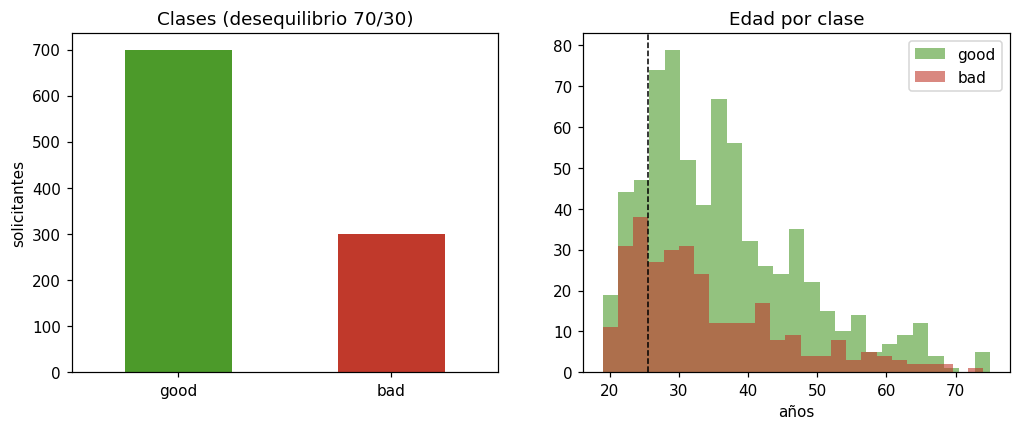

,solicitantes,tasa de impago real
>25 años,810,0.272
≤25 años,190,0.421


In [67]:
# Descripción básica para la wiki (apartado 1.4)
display(X[COLS_NUM].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y.map({0: "good", 1: "bad"}).value_counts().plot.bar(ax=axes[0], rot=0, color=["#4c9a2a", "#c0392b"])
axes[0].set_title("Clases (desequilibrio 70/30)"); axes[0].set_ylabel("solicitantes"); axes[0].set_xlabel("")
for label, color in ((0, "#4c9a2a"), (1, "#c0392b")):
    axes[1].hist(X.loc[y == label, "age"], bins=25, alpha=0.6, color=color, label=["good", "bad"][label])
axes[1].axvline(pc.CUTOFF_AGE + 0.5, color="k", ls="--", lw=1); axes[1].legend()
axes[1].set_title("Edad por clase"); axes[1].set_xlabel("años")
storage("1_4_clases_y_edad.png")

# Tasa de impago por grupo de edad: ayuda a interpretar luego la equidad (4.2)
group = np.where(X["age"] <= pc.CUTOFF_AGE, f"≤{pc.CUTOFF_AGE} años", f">{pc.CUTOFF_AGE} años")
pd.DataFrame({"solicitantes": pd.Series(group).value_counts(),
              "tasa de impago real": y.groupby(group).mean().round(3)})

**Limitaciones:** datos antiguos, solo 1.000 casos, desequilibrio de clases, variables codificadas y errores de codificación documentados por Grömping (2019). `personal_status` mezcla sexo y estado civil, así que **el sexo no se puede obtener de forma fiable**: para la equidad usamos la **edad**. Si los jóvenes tienen más impagos reales en estos datos, parte de la diferencia que veamos en 4.2 vendrá de los datos y no solo del modelo.

## 1.5. Partición y protocolo experimental

- **Partición:** 80 % entrenamiento / 20 % test, estratificada, semilla fija. Los índices del test se guardan en `common/test_index.csv`. El test **solo se usa una vez**, en la evaluación final de cada modelo.
- **Preprocesado:** `pc.create_preprocess(X_train)` dentro de un `Pipeline` (sin fugas). El subgrupo A puede usar `escalar=True` para la regresión logística.
- **Validación cruzada:** `pc.evaluate_cv(...)`: 5 particiones estratificadas × 3 repeticiones sobre el 80 % de entrenamiento. Sirve para elegir hiperparámetros y dar resultados como media ± desviación.
- **Umbral:** se deniega si P(bad) ≥ umbral. Cada modelo usa el umbral que minimiza el coste en sus predicciones fuera de muestra (`pc.choose_thres`), es decir, **el mismo criterio** para todos.

In [68]:
from sklearn.model_selection import train_test_split
_, idx_test = train_test_split(X.index, test_size=pc.TEST_SIZE, stratify=y, random_state=pc.SEED)
pd.Series(sorted(idx_test), name="index").to_csv(os.path.join(R["common"], "test_index.csv"), index=False)

X_train, X_test, y_train, y_test = pc.load_partition(FOLDER)
pd.DataFrame({"solicitantes": [len(y_train), len(y_test)],
              "proporción bad": [round(y_train.mean(), 3), round(y_test.mean(), 3)],
              "proporción ≤25 años": [round((X_train.age <= pc.CUTOFF_AGE).mean(), 3), round((X_test.age <= pc.CUTOFF_AGE).mean(), 3)]},
             index=["train", "test"])

,solicitantes,proporción bad,proporción ≤25 años
train,800,0.3,0.182
test,200,0.3,0.220


## 1.6. Criterios de comparación

| Criterio | Cómo se mide |
|---|---|
| Rendimiento | AUC · sensibilidad en `bad` · especificidad en `good` · **coste medio** = (5 × malos aprobados + 1 × buenos denegados) / n |
| Variabilidad | media ± desviación en la validación cruzada |
| Estabilidad de las explicaciones | Jaccard medio del top-5 de variables entre ejecuciones/particiones (1 = siempre las mismas) |
| Equidad | diferencias entre ≤25 y >25 años en tasa de concesión, buenos denegados y malos detectados (`pc.equity`) |
| Comprensibilidad y auditoría | lista de comprobación común de 9 preguntas, respondida para cada modelo (`pc.storage_auditory`) |

**Modelo de referencia:** un modelo trivial que no aprende nada (siempre predice la proporción de `bad`). Marca el mínimo que cualquier modelo debe superar.

In [69]:
from sklearn.dummy import DummyClassifier
trivial = lambda: DummyClassifier(strategy="prior")
table_cv, thres, _ = pc.evaluate_csv(trivial, X_train, y_train)
res_test = pc.metrics(y_test, trivial().fit(X_train, y_train).predict_proba(X_test)[:, 1], thres)
pc.storage_results(FOLDER, "Referencia", "trivial", table_cv, thres, res_test)
print(f"Umbral elegido: {thres:.2f} (con probabilidad constante 0,30 equivale a denegar a todos)")
pd.DataFrame({"Validación cruzada": pc.summary_csv(table_cv), "Test": pd.Series(res_test).round(3)})

Umbral elegido: 0.05 (con probabilidad constante 0,30 equivale a denegar a todos)


,Validación cruzada,Test
AUC,0.500 ± 0.000,0.5
Sensibilidad (bad),1.000 ± 0.000,1.0
Especificidad (good),0.000 ± 0.000,0.0
Coste medio,0.700 ± 0.000,0.7


In [70]:
print("Lista de comprobación común de auditoría (cada subgrupo la responde para sus modelos):\n")
print("\n".join(pc.AUDIT_LIST))

Lista de comprobación común de auditoría (cada subgrupo la responde para sus modelos):

1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?
2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?
3. ¿La explicación sale del propio modelo o de una aproximación externa?
4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?
5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?
6. ¿Se puede comprobar la equidad por grupos de edad?
7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?
8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?
9. ¿Está documentado con una model card completa?
